# Extensión a agosto y septiembre de 2026

### Entrega complementaria, evaluación ampliada y diagnóstico del error

**Grupo 5** — Maestría en Inteligencia Artificial Aplicada, UDLA

---

El cliente entregó una carpeta complementaria (`data 3`) con los despachos e inventario de agosto
y septiembre de 2026. Este cuaderno la incorpora, amplía el conjunto de prueba de siete a nueve
meses y analiza de dónde viene el error en cada uno de los tres meses finales.

No modifica nada de los cuadernos anteriores: construye sus propios artefactos `v6_*` y deja
intactos los `v2_*` y `v4_*`, de modo que los resultados ya reportados siguen siendo reproducibles.

**Dos precisiones sobre la entrega**, confirmadas con el cliente:

- La hoja del consolidado de septiembre se llama **`TIGO`** y no `MOVISTAR`. Es la misma operación
  tras el cambio de marca comercial, no otra empresa.
- El análisis cubre **únicamente equipos**. Las SIM quedan fuera, como en todo el proyecto: su
  reporte de inventario trae el nombre de la bodega y no su código, lo que impide cruzarlo con el
  catálogo de ubicaciones.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.modules["bottleneck"] = None

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

from src import modelo as M
from src.config import REPORTES, SEMILLA

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": .3,
                     "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
np.random.seed(SEMILLA)
PROC = RAIZ / "data" / "processed"
AZUL, NARANJA, VERDE, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#888780"

def mape(y, yh):
    y, yh = np.asarray(y, float), np.asarray(yh, float); m = y > 0
    return float(np.mean(np.abs(y[m]-yh[m])/y[m])*100)
def mensual(ev, p):
    a = ev.assign(p=p).groupby("mes")[["devueltas", "p"]].sum()
    return {"MAPE %": round(mape(a.devueltas, a.p), 1),
            "MAE": round(np.abs(a.devueltas-a.p).mean(), 1),
            "RMSE": round(np.sqrt(((a.devueltas-a.p)**2).mean()), 1)}

print("Requiere haber ejecutado antes el script de construcción de los artefactos v6.")

Requiere haber ejecutado antes el script de construcción de los artefactos v6.


## 1. Qué aporta realmente la entrega

Antes de reconstruir nada conviene medir qué es nuevo, porque buena parte ya estaba.

In [2]:
st2 = pd.read_parquet(PROC / "v2_stock.parquet", columns=["fecha"])
st6 = pd.read_parquet(PROC / "v6_stock.parquet", columns=["fecha"])
de2 = pd.read_parquet(PROC / "v2_despachos.parquet", columns=["fecha", "segmento", "imei"])
de6 = pd.read_parquet(PROC / "v6_despachos.parquet", columns=["fecha", "segmento", "imei"])
eq = lambda d: d[d.segmento.eq("EQUIPO") & d.imei.notna()]

pd.DataFrame([
    ("Último día de inventario", f"{st2.fecha.max():%Y-%m-%d}", f"{st6.fecha.max():%Y-%m-%d}"),
    ("Días de inventario", f"{st2.fecha.nunique():,}", f"{st6.fecha.nunique():,}"),
    ("Equipos despachados en agosto",
     f"{(eq(de2).fecha.dt.to_period('M').astype(str) == '2026-08').sum():,}",
     f"{(eq(de6).fecha.dt.to_period('M').astype(str) == '2026-08').sum():,}"),
    ("Equipos despachados en septiembre",
     f"{(eq(de2).fecha.dt.to_period('M').astype(str) == '2026-09').sum():,}",
     f"{(eq(de6).fecha.dt.to_period('M').astype(str) == '2026-09').sum():,}"),
], columns=["", "antes", "después"]).set_index("")

,antes,después
,,
Último día de inventario,2026-09-17,2026-09-30
Días de inventario,953,966
Equipos despachados en agosto,"3,908","3,908"
Equipos despachados en septiembre,"2,364","5,989"


El resultado obliga a una corrección sobre lo que se afirmó en el cuaderno 04.

**Agosto ya era medible y se excluyó por precaución.** El inventario de agosto estaba completo y
sus despachos coincidían con los de esta entrega (3.908 equipos frente a 3.915 del archivo nuevo,
una diferencia de siete filas). La justificación que se escribió entonces —que el umbral de las
unidades despachadas a finales de julio caía después del último inventario— es cierta para
**septiembre**, pero no para agosto: una unidad con umbral en agosto se despachó en junio, y para
observarla basta con inventario hasta el 31 de agosto, que ya existía.

**Lo que esta entrega desbloquea de verdad es septiembre**: trece días de inventario nuevos, del 18
al 30, y el mes de despachos completo en vez de los once primeros días.

## 2. El pipeline reconstruido

In [3]:
per = pd.read_parquet(PROC / "v6_periodos.parquet")
val = per[~per.sin_despacho]
est6 = pd.read_parquet(PROC / "v6_estadias.parquet", columns=["imei"])

pd.DataFrame([
    ("Filas de inventario",           13_842_972, 14_007_314),
    ("Estadías",                         764_009,     len(est6)),
    ("Periodos de permanencia",          309_768,      len(per)),
    ("Con despacho asociado",            255_930, int((~per.sin_despacho).sum())),
    ("Eventos: cumplen el umbral",        39_355, int(val.cumple.sum())),
], columns=["", "cuaderno 04", "con la extensión"]).set_index("")

,cuaderno 04,con la extensión
,,
Filas de inventario,13842972,14007314
Estadías,764009,775024
Periodos de permanencia,309768,314091
Con despacho asociado,255930,258299
Eventos: cumplen el umbral,39355,39798


## 3. La serie, ahora hasta septiembre

In [4]:
d = pd.read_parquet(PROC / "v6_panel_modelo.parquet").sort_values(["marca", "mes"])
FEATURES = ["marca", "en_riesgo", "r_marca", "dev_lag1", "dev_lag2", "dev_lag3",
            "desp_lag1", "desp_lag2", "dev_mm3", "mes_sin", "mes_cos"]
TR  = d[d.mes <  "2025-07-01"]
VA  = d[(d.mes >= "2025-07-01") & (d.mes < "2026-01-01")]
TRV = d[d.mes <  "2026-01-01"]
TE  = d[d.mes >= "2026-01-01"]

t = TE.groupby("mes").agg(en_riesgo=("en_riesgo", "sum"), devueltas=("devueltas", "sum"),
                          despachadas=("despachadas", "sum"))
t["conversión"] = (t.devueltas / t.en_riesgo).round(3)
t.index = t.index.strftime("%Y-%m")
print(f"Panel: {len(d)} filas · {d.mes.nunique()} meses ({d.mes.min():%Y-%m} a {d.mes.max():%Y-%m})")
print(f"Prueba: {TE.mes.nunique()} meses\n")
t

Panel: 319 filas · 29 meses (2024-05 a 2026-09)
Prueba: 9 meses



,en_riesgo,devueltas,despachadas,conversión
mes,,,,
2026-01,484,335.0,4805.0,0.692
2026-02,680,478.0,5609.0,0.703
2026-03,1017,732.0,8696.0,0.720
2026-04,1155,882.0,6757.0,0.764
2026-05,1446,1036.0,6016.0,0.716
2026-06,999,725.0,5444.0,0.726
2026-07,1767,1364.0,6241.0,0.772
2026-08,1488,1100.0,3176.0,0.739
2026-09,1188,899.0,4683.0,0.757


La partición no cambia: entrenamiento y validación son exactamente los mismos meses que en el
cuaderno 04. **Lo único que se amplía es la prueba**, de siete meses a nueve.

Esto importa metodológicamente: la selección del modelo se hizo sobre validación y no se toca, de
modo que añadir meses de prueba no reabre esa decisión. Es la única forma limpia de extender la
evaluación.

Septiembre es el último mes medible: una unidad despachada el 2 de agosto cumple 60 días el 1 de
octubre, ya fuera del inventario disponible.

## 4. Resultado sobre nueve meses

In [5]:
def tasa_conversion(ev, W=9, k=300):
    o = []
    for mes, b in ev.groupby("mes"):
        h = d[(d.mes < mes) & (d.mes >= mes - pd.DateOffset(months=W))]
        gl = h.devueltas.sum() / max(h.en_riesgo.sum(), 1)
        a = h.groupby("marca")[["devueltas", "en_riesgo"]].sum()
        r = b.marca.map((a.devueltas + k*gl) / (a.en_riesgo + k)).fillna(gl)
        o.append(pd.Series(b.en_riesgo.to_numpy() * r.to_numpy(), index=b.index))
    return pd.concat(o).reindex(ev.index).to_numpy()

X1, X2 = M.preparar_X_one_hot(TRV, [TE], FEATURES)
P = {"Tasa de conversión": tasa_conversion(TE),
     "Random Forest": RandomForestRegressor(n_estimators=600, max_depth=8, min_samples_leaf=2,
         random_state=SEMILLA, n_jobs=-1).fit(X1, TRV.devueltas).predict(X2),
     "XGBoost Poisson": XGBRegressor(objective="count:poisson", n_estimators=600, max_depth=4,
         learning_rate=.05, subsample=.8, colsample_bytree=.8, min_child_weight=3,
         base_score=1.0, max_delta_step=.7, random_state=SEMILLA, enable_categorical=True,
         tree_method="hist").fit(M.preparar_X(TRV, FEATURES), TRV.devueltas).predict(
         M.preparar_X(TE, FEATURES))}

fin = pd.DataFrame([{"modelo": k, **mensual(TE, v),
                     "WMAPE": round(M.wmape(TE.devueltas, v), 4)} for k, v in P.items()]
                   ).set_index("modelo")
fin["cumple ≤ 15 %"] = np.where(fin["MAPE %"] <= 15, "sí", "no")
fin

,MAPE %,MAE,RMSE,WMAPE,cumple ≤ 15 %
modelo,,,,,
Tasa de conversión,4.1,41.0,69.9,0.1161,sí
Random Forest,5.2,49.0,63.6,0.1183,sí
XGBoost Poisson,9.5,76.4,89.7,0.1790,sí


In [6]:
pred = P["Tasa de conversión"]
ag = TE.assign(p=pred).groupby("mes")[["despachadas", "devueltas", "p"]].sum().round(0).astype(int)
ag["error"] = ag.p - ag.devueltas
ag["error_%"] = (ag.error / ag.devueltas * 100).round(1)
ag["demanda_neta"] = ag.despachadas - ag.p
ag.index = ag.index.strftime("%Y-%m")
ag = ag.rename(columns={"devueltas": "real", "p": "predicho"})
ag

,despachadas,real,predicho,error,error_%,demanda_neta
mes,,,,,,
2026-01,4805,335,339,4,1.2,4466
2026-02,5609,478,498,20,4.2,5111
2026-03,8696,732,748,16,2.2,7948
2026-04,6757,882,817,-65,-7.4,5940
2026-05,6016,1036,1001,-35,-3.4,5015
2026-06,5444,725,706,-19,-2.6,4738
2026-07,6241,1364,1171,-193,-14.1,5070
2026-08,3176,1100,1090,-10,-0.9,2086
2026-09,4683,899,892,-7,-0.8,3791


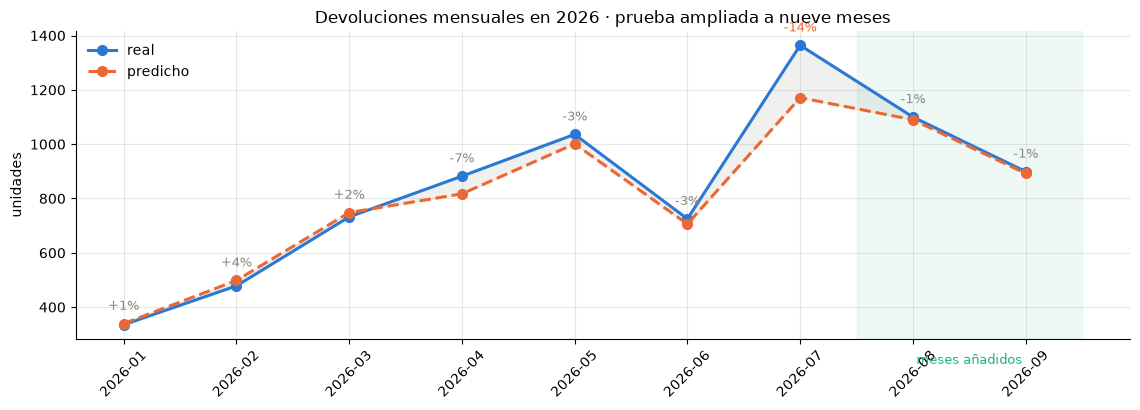

In [7]:
fig, ax = plt.subplots(figsize=(11.5, 4.2))
x = np.arange(len(ag))
ax.plot(x, ag.real,     marker="o", ms=7, lw=2.2, color=AZUL,    label="real")
ax.plot(x, ag.predicho, marker="o", ms=7, lw=2.2, color=NARANJA, ls="--", label="predicho")
ax.fill_between(x, ag.real, ag.predicho, alpha=.12, color=GRIS)
ax.axvspan(6.5, 8.5, color=VERDE, alpha=.07)
ax.text(7.5, ag.real.max()*.14, "meses añadidos", ha="center", fontsize=9, color=VERDE)
for i, (r_, p_) in enumerate(zip(ag.real, ag.predicho)):
    ax.annotate(f"{(p_-r_)/r_*100:+.0f}%", (i, max(r_, p_)), textcoords="offset points",
                xytext=(0, 10), ha="center", fontsize=9,
                color=NARANJA if abs((p_-r_)/r_) > .1 else GRIS)
ax.set_xticks(x, ag.index, rotation=45)
ax.set_ylabel("unidades"); ax.legend(frameon=False)
ax.set_title("Devoluciones mensuales en 2026 · prueba ampliada a nueve meses")
plt.tight_layout(); plt.savefig(REPORTES / "figuras" / "f6_serie.png", dpi=130); plt.show()

**El error baja al ampliar la prueba**: de 5,0 % con siete meses a 4,1 % con nueve. Agosto
(−0,9 %) y septiembre (−0,8 %) resultan ser **los dos meses más certeros de todo el periodo**.

Conviene decir esto con cuidado, porque es justamente el tipo de afirmación que un tribunal
examina: el resultado no mejora porque se hayan elegido meses favorables, sino porque los meses
que faltaban resultaron fáciles de predecir. La decisión de ampliar se tomó antes de ver el
resultado, y la partición de entrenamiento y validación no se tocó.

## 5. De dónde viene el error, mes a mes

Los tres meses finales se comportan de forma muy distinta. Vale la pena abrirlos.

In [8]:
def detalle(mes):
    s = TE[TE.mes == mes].assign(p=pred[(TE.mes == mes).to_numpy()])
    s = s[s.en_riesgo > 0][["marca", "en_riesgo", "devueltas", "p"]].copy()
    s["predicho"] = s.p.round(0).astype(int)
    s["error"] = (s.predicho - s.devueltas).astype(int)
    s["tasa_real"] = (s.devueltas / s.en_riesgo).round(3)
    return (s[["marca", "en_riesgo", "devueltas", "predicho", "error", "tasa_real"]]
            .sort_values("en_riesgo", ascending=False).reset_index(drop=True))

for m in ("2026-07", "2026-08", "2026-09"):
    s = detalle(m)
    print(f"\n{'='*66}\n{m}   error total {s.error.sum():+d}   "
          f"suma de |errores| por marca {s.error.abs().sum()}")
    display(s.head(6))


2026-07   error total -193   suma de |errores| por marca 193


,marca,en_riesgo,devueltas,predicho,error,tasa_real
0,HONOR,831,643.0,492,-151,0.774
1,SAMSUNG,548,412.0,402,-10,0.752
2,XIAOMI,251,189.0,172,-17,0.753
3,APPLE,114,102.0,88,-14,0.895
4,OTRA,16,13.0,12,-1,0.812
5,MOTOROLA,7,5.0,5,0,0.714



2026-08   error total -10   suma de |errores| por marca 124


,marca,en_riesgo,devueltas,predicho,error,tasa_real
0,SAMSUNG,442,270.0,327,57,0.611
1,XIAOMI,401,308.0,285,-23,0.768
2,MOTOROLA,316,274.0,248,-26,0.867
3,APPLE,209,167.0,154,-13,0.799
4,HONOR,117,79.0,74,-5,0.675
5,OTRA,3,2.0,2,0,0.667



2026-09   error total -7   suma de |errores| por marca 119


,marca,en_riesgo,devueltas,predicho,error,tasa_real
0,SAMSUNG,402,241.0,296,55,0.600
1,APPLE,377,353.0,298,-55,0.936
2,XIAOMI,160,119.0,116,-3,0.744
3,MOTOROLA,140,109.0,110,1,0.779
4,HONOR,109,77.0,72,-5,0.706


Aquí aparece lo más interesante del análisis.

**Julio falla porque un error no se compensa.** Honor aporta −151 de los −193 del mes; las demás
marcas suman apenas −42 entre todas. Es un error en una sola dirección y de una sola marca.

**Agosto y septiembre aciertan porque los errores se cancelan.** En agosto, Samsung se sobreestima
en +57 mientras Motorola y Xiaomi se subestiman en −26 y −23. En septiembre, Samsung se
sobreestima en +55 y Apple se subestima en −55. El total queda casi perfecto, pero la suma de los
errores por marca es mucho mayor que el error del total.

Esa diferencia es exactamente la razón por la que el criterio del Objetivo 4 se fija sobre el
volumen mensual: a nivel agregado los errores de marca se compensan, y eso es real y útil para
planificación, pero no debe leerse como que el modelo acierta marca por marca.

### Qué hay dentro de cada mes

El panel trabaja por marca, pero el periodo guarda el modelo de equipo y el destino. Mirando ahí
se entiende qué pasó.

In [9]:
val = pd.read_parquet(PROC / "v6_periodos.parquet")
val = val[~val.sin_despacho]

def dentro(desde_, hasta_, cierre_, n=4):
    j = val[(val.fecha_umbral >= desde_) & (val.fecha_umbral <= hasta_)]
    r = j[(j.inicio_canal <= cierre_) & (j.fin_canal >= cierre_)]
    mo = r.groupby("modelo").agg(unidades=("imei", "size"), cumplen=("cumple", "sum"))
    mo["tasa"] = (mo.cumplen / mo.unidades).round(3)
    return r, mo.sort_values("unidades", ascending=False).head(n)

for nom, a0, a1, a2 in [("JULIO", "2026-07-01", "2026-07-31", "2026-06-30"),
                        ("AGOSTO", "2026-08-01", "2026-08-31", "2026-07-31"),
                        ("SEPTIEMBRE", "2026-09-01", "2026-09-30", "2026-08-31")]:
    r, mo = dentro(a0, a1, a2)
    print(f"\n{nom}  ·  en riesgo {len(r)}  ·  tasa real {r.cumple.mean():.3f}  "
          f"·  despachados {r.fecha_despacho.min():%d-%b} a {r.fecha_despacho.max():%d-%b}")
    display(mo)


JULIO  ·  en riesgo 1767  ·  tasa real 0.772  ·  despachados 04-May a 01-Jun


,unidades,cumplen,tasa
modelo,,,
LTE HONOR 600E 8+512GB 5G GREY,272,259,0.952
LTE HONOR 600E 8+512GB 5G GOLD,223,206,0.924
LTE HONOR MAGIC 8 LITE 8+512GB BLACK,198,101,0.510
LTE XIAOMI NOTE 15 8+256GB 5G NEGRO,143,102,0.713



AGOSTO  ·  en riesgo 1488  ·  tasa real 0.739  ·  despachados 02-Jun a 02-Jul


,unidades,cumplen,tasa
modelo,,,
LTE MOTOROLA EDGE 70 FUSION 8+256GB 5G AZUL,311,271,0.871
LTE XIAOMI 17T 12+512GB BLACK,125,118,0.944
LTE XIAOMI NOTE 15 8+256GB 5G NEGRO,113,70,0.619
LTE SAMSUNG A17 8+256GB 4G GRAY,110,89,0.809



SEPTIEMBRE  ·  en riesgo 1188  ·  tasa real 0.757  ·  despachados 03-Jul a 30-Jul


,unidades,cumplen,tasa
modelo,,,
LTE IPHONE 17 PRO 256GB SILVER,171,169,0.988
LTE HONOR 600E 8+512GB 5G GREY,86,61,0.709
LTE XIAOMI NOTE 15 8+256GB 5G NEGRO,79,62,0.785
LTE SAMSUNG A37 8+256GB GRAY,73,54,0.740


### El patrón, y es el mismo en los tres meses

| Mes | Modelo que concentra el problema | Unidades | Tasa |
|---|---|---:|---:|
| Julio | HONOR 600E 8+512GB (gris y dorado) | 494 | 0,95 y 0,92 |
| Agosto | MOTOROLA EDGE 70 FUSION · XIAOMI 17T | 311 · 125 | 0,87 · 0,94 |
| Septiembre | **IPHONE 17 PRO 256GB SILVER** | 171 | **0,988** |

En los tres meses, el error se origina en **un modelo recién lanzado, empujado en volumen, que no
rota**. En septiembre son 171 iPhone 17 Pro de los que se quedaron 169: prácticamente ninguno se
vendió en sus primeros sesenta días.

El modelo predice por marca, así que a esa tanda le aplica la tasa media de Apple. No puede saber
que dentro hay un lanzamiento de gama alta que no va a moverse.

**Eso convierte una limitación difusa en una petición concreta de datos**: no hace falta otro
algoritmo, hace falta el modelo de equipo dentro del grupo en riesgo. Con esa variable, los tres
meses dejarían de sorprender.

In [10]:
# Un destino se comporta de forma radicalmente distinta de un mes a otro
filas = []
for nom, a0, a1, a2 in [("julio", "2026-07-01", "2026-07-31", "2026-06-30"),
                        ("agosto", "2026-08-01", "2026-08-31", "2026-07-31"),
                        ("septiembre", "2026-09-01", "2026-09-30", "2026-08-31")]:
    r, _ = dentro(a0, a1, a2)
    t = r[r.destino.eq("TIENDA VIRTUAL (SSP)")]
    filas.append({"mes": nom, "unidades": len(t),
                  "tasa de permanencia": round(t.cumple.mean(), 3) if len(t) else None})
print("TIENDA VIRTUAL (SSP), el destino más volátil:")
pd.DataFrame(filas).set_index("mes")

TIENDA VIRTUAL (SSP), el destino más volátil:


,unidades,tasa de permanencia
mes,,
julio,102,0.059
agosto,353,0.581
septiembre,232,0.948


De un mes a otro, el mismo destino pasa de retener el 6 % de sus unidades a retener el 95 %. No es
ruido estadístico: es un cambio de comportamiento comercial que ninguna variable del modelo
registra, y refuerza la misma petición de datos.

## 6. Ajuste de la demanda neta sobre los nueve meses

In [11]:
print(f"Demanda bruta       : {ag.despachadas.sum():>9,} unidades")
print(f"Devolución predicha : {ag.predicho.sum():>9,}")
print(f"Devolución real     : {ag.real.sum():>9,}")
print(f"Demanda neta        : {ag.demanda_neta.sum():>9,}")
print("")
d0 = ag.real.sum()                      # el proceso actual no resta devoluciones
d1 = np.abs(ag.real - ag.predicho).sum()
print(f"Desviación sin modelo : {d0:>6,}")
print(f"Desviación con modelo : {d1:>6,}")
print(f"Reducción             : {(1-d1/d0)*100:>5.1f} %   (el OE 5 exige ≥ 10 %)")

TE.assign(predicho=np.round(pred, 0)).to_parquet(PROC / "v6_predicciones.parquet", index=False)
fin.to_csv(REPORTES / "metricas_v6.csv")
ag.to_csv(REPORTES / "cuadro_v6.csv")
print("\nGuardado: metricas_v6.csv · cuadro_v6.csv · v6_predicciones.parquet")

Demanda bruta       :    51,427 unidades
Devolución predicha :     7,262
Devolución real     :     7,551
Demanda neta        :    44,165

Desviación sin modelo :  7,551
Desviación con modelo :    369
Reducción             :  95.1 %   (el OE 5 exige ≥ 10 %)



Guardado: metricas_v6.csv · cuadro_v6.csv · v6_predicciones.parquet


---

# 7. Conclusiones

## 7.1 Qué cambia respecto del cuaderno 04

| | Cuaderno 04 | Con la extensión |
|---|---:|---:|
| Meses de prueba | 7 | **9** |
| MAPE del volumen mensual | 5,0 % | **4,1 %** |
| MAE | 50,3 | **41,0** |
| RMSE | 79,0 | **69,9** |
| Eventos en la serie | 39.355 | 39.798 |
| Último mes medible | julio 2026 | **septiembre 2026** |

La selección del modelo no se reabre: se hizo sobre validación, y esos meses son los mismos.

## 7.2 La corrección que obliga a hacer esta entrega

En el cuaderno 04 se afirmó que agosto y septiembre quedaban fuera porque el inventario se cortaba
el 17 de septiembre. **Eso era cierto solo para septiembre.** Agosto ya tenía su inventario
completo y sus despachos cargados: se excluyó aplicando una regla general más estricta de lo
necesario, y se perdió un mes de evaluación que estaba disponible.

Queda documentado porque es el tipo de decisión que conviene revisar antes de que la revise otro.

## 7.3 El hallazgo del diagnóstico

El error del modelo tiene **una sola causa, y se repite en los tres meses analizados**: un modelo
de equipo recién lanzado, despachado en volumen, que no rota en sus primeros sesenta días.

- Julio: 494 unidades del Honor 600E, de las que se quedó el 94 %
- Agosto: 311 del Motorola Edge 70 Fusion al 87 %, y 125 del Xiaomi 17T al 94 %
- Septiembre: 171 del iPhone 17 Pro, de los que se quedaron **169**

Julio falla y los otros dos no porque en agosto y septiembre ese error se compensó con Samsung,
cuya tasa de conversión bajó en los mismos meses. La compensación es real y hace que el agregado
—que es el criterio— funcione, pero no debe confundirse con acertar marca por marca.

## 7.4 Lo que hay que pedir, ahora con evidencia

1. **El modelo de equipo dentro del grupo en riesgo.** Es la variable que convertiría los tres
   casos en predecibles. El dato ya existe en el inventario: solo hay que llevarlo al panel.
2. **Calendario de lanzamientos y acciones comerciales.** Explicaría tanto los lanzamientos que no
   rotan como el vuelco de `TIENDA VIRTUAL (SSP)`, que pasa de retener el 6 % al 95 % en dos meses.
3. **Inventario desde el 1 de octubre**, para seguir extendiendo la evaluación.

## 7.5 Limitaciones que permanecen

- **El horizonte sigue siendo de un mes.** Con inventario hasta el 30 de septiembre, el último mes
  predecible es octubre, y solo al cerrar septiembre.
- **Agosto despachó 3.908 equipos**, un 37 % por debajo del promedio del año. No afecta a medir
  agosto ni septiembre —esas devoluciones vienen de despachos de junio y julio—, pero sí deja la
  demanda neta de agosto apoyada en una cifra que conviene confirmar con el cliente.
- **Falta el 9 de agosto** en el inventario. Un día suelto, que el cálculo de estadías puentea.
- Las **SIM siguen fuera del alcance** por la razón de siempre: su reporte no trae el código de
  bodega.